# MovieLens 1M — exploratory data analysis

A short look at the interaction log the recommenders are trained on: how active users are, how skewed item popularity is, how events are spread over time, and what that implies for the leave-one-out-by-time evaluation.

Run `python scripts/download_data.py` first; this notebook reads `data/processed/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recsys.data import ProcessedData, build_split, dataset_stats

DATA_DIR = Path('..') / 'data' / 'processed'
processed = ProcessedData.load(DATA_DIR)
log, items = processed.interactions, processed.items

# Chart style: light surface, recessive axes, fixed categorical order.
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.titlecolor': INK, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'lines.linewidth': 2,
    'figure.dpi': 110,
})

pd.Series(dataset_stats(processed)).to_frame('value')

,value
users,6040
items,3706
interactions,1000209
density_%,4.468363
per_user_min,20
per_user_median,96.0
per_user_mean,165.597517
per_user_max,2314
per_item_min,1
per_item_median,123.5


## Interactions per user

Every user has at least 20 ratings (a property of ML-1M), but activity is heavy-tailed: the median user has ~96 ratings, the most active over 2,000.

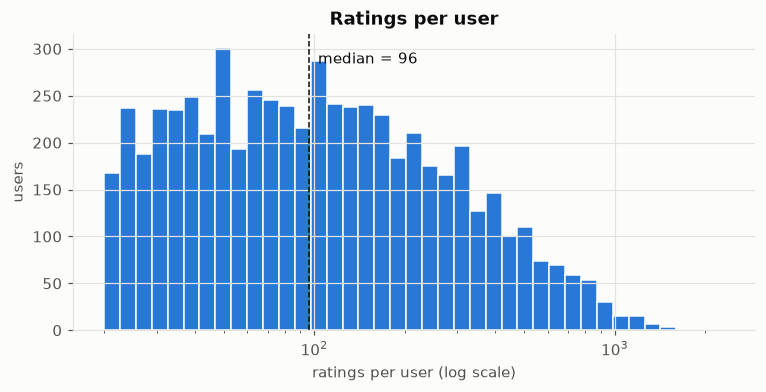

,count,mean,std,min,10%,50%,90%,99%,max
ratings per user,6040.0,165.6,192.7,20.0,27.0,96.0,400.0,906.7,2314.0


In [2]:
per_user = log.groupby('user_idx').size()
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 40)
ax.hist(per_user, bins=bins, color=BLUE, edgecolor='#fcfcfb', linewidth=1)
ax.set_xscale('log')
ax.axvline(per_user.median(), color=INK, linewidth=1, linestyle='--')
ax.annotate(f'median = {per_user.median():.0f}', (per_user.median(), ax.get_ylim()[1] * 0.9),
            xytext=(6, 0), textcoords='offset points', color=INK)
ax.set(title='Ratings per user', xlabel='ratings per user (log scale)', ylabel='users')
plt.show()
per_user.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1).to_frame('ratings per user').T

## Item popularity: the long tail

A small head of blockbusters collects a large share of all interactions. This is why the *Most Popular* baseline is non-trivial, and why in-batch negatives (two-tower) need a popularity (logQ) correction.

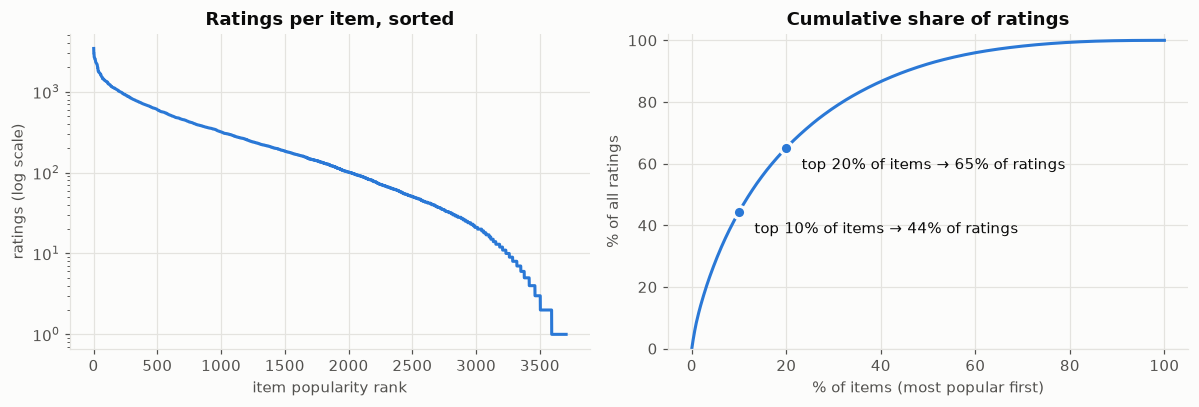

Items with < 10 ratings: 12.0% of the catalogue


In [3]:
per_item = log.groupby('item_idx').size().sort_values(ascending=False)
share = per_item.cumsum() / per_item.sum()
rank_pct = np.arange(1, len(per_item) + 1) / len(per_item) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(np.arange(1, len(per_item) + 1), per_item.to_numpy(), color=BLUE)
ax1.set_yscale('log')
ax1.set(title='Ratings per item, sorted', xlabel='item popularity rank', ylabel='ratings (log scale)')

ax2.plot(rank_pct, share.to_numpy() * 100, color=BLUE)
for pct in (10, 20):
    covered = share.iloc[int(len(per_item) * pct / 100) - 1] * 100
    ax2.plot([pct], [covered], 'o', color=BLUE, markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=2)
    ax2.annotate(f'top {pct}% of items → {covered:.0f}% of ratings', (pct, covered),
                 xytext=(10, -14), textcoords='offset points', color=INK)
ax2.set(title='Cumulative share of ratings', xlabel='% of items (most popular first)',
        ylabel='% of all ratings', ylim=(0, 102))
fig.tight_layout()
plt.show()
print(f'Items with < 10 ratings: {(per_item < 10).mean():.1%} of the catalogue')

Most popular movies (these are what the popularity fallback serves to unknown users):

In [4]:
top = per_item.head(10).rename('ratings').reset_index()
top.merge(items, on='item_idx')[['title', 'genres', 'ratings']]

,title,genres,ratings
0,American Beauty (1999),Comedy|Drama,3428
1,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi,2991
2,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,2990
3,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,2883
4,Jurassic Park (1993),Action|Adventure|Sci-Fi,2672
5,Saving Private Ryan (1998),Action|Drama|War,2653
6,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller,2649
7,"Matrix, The (1999)",Action|Sci-Fi|Thriller,2590
8,Back to the Future (1985),Comedy|Sci-Fi,2583
9,"Silence of the Lambs, The (1991)",Drama|Thriller,2578


## Events over time

Most ratings were made in the first months after the users joined (mid/late 2000); the long 2001–2003 tail comes from fewer, long-lived users. A global time split would therefore leave many users with no test events — hence the per-user leave-one-out split.

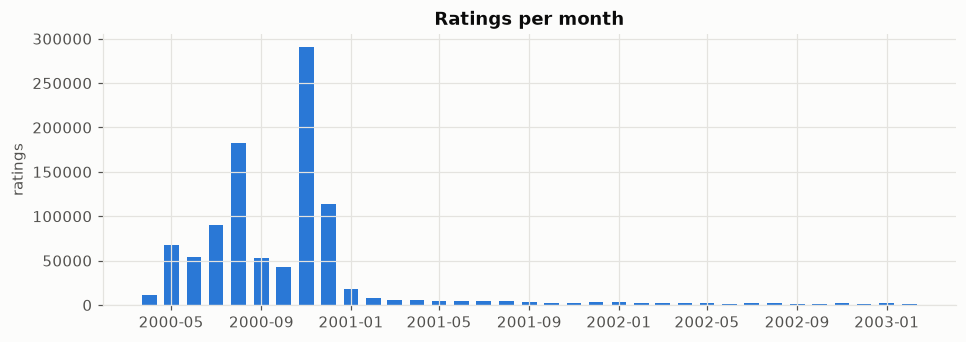

In [5]:
months = pd.to_datetime(log['timestamp'], unit='s').dt.to_period('M')
monthly = months.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(monthly.index.to_timestamp(), monthly.to_numpy(), width=20, color=BLUE)
ax.set(title='Ratings per month', ylabel='ratings')
plt.show()

## Timestamp ties and the leave-one-out split

Users often rated many movies within the same second (bulk rating sessions), so "the last interaction" is not always unique. Preprocessing sorts by timestamp with a *stable* sort, keeping the original file order for ties, which makes the split deterministic.

In [6]:
same_ts = log.groupby('user_idx')['timestamp'].diff().eq(0)
print(f'Consecutive events sharing a timestamp: {same_ts.mean():.1%}')

split = build_split(processed)
train_len = pd.Series([len(h) for h in split.history('valid')])
print(f'Users: {split.n_users:,}  |  train events: {train_len.sum():,}  |  '
      f'valid/test events: {split.n_users:,} each')
print(f'Users whose train history exceeds SASRec max_len=200: {(train_len > 200).mean():.1%}')

Consecutive events sharing a timestamp: 52.9%
Users: 6,040  |  train events: 988,129  |  valid/test events: 6,040 each
Users whose train history exceeds SASRec max_len=200: 25.8%
